In [1]:
%pip install pandas xlrd matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
df = pd.read_excel("https://github.com/Bency1999/Data-Analytics-Final-Project-/raw/main/Absenteeism_at_work.xls")

C:\Users\bency\AppData\Local\Temp\ipykernel_23820\737330928.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel("https://github.com/Bency1999/Data-Analytics-Final-Project-/raw/main/Absenteeism_at_work.xls")


In [2]:
df.head()

,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,...,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
0,11,26,7,3,1,289,36,13,33,239554,...,0,1,2,1,0,1,90,172,30,4
1,36,0,7,3,1,118,13,18,50,239554,...,1,1,1,1,0,0,98,178,31,0
2,3,23,7,4,1,179,51,18,38,239554,...,0,1,0,1,0,0,89,170,31,2
3,7,7,7,5,1,279,5,14,39,239554,...,0,1,2,1,1,0,68,168,24,4
4,11,23,7,5,1,289,36,13,33,239554,...,0,1,2,1,0,1,90,172,30,2


In [3]:
print(df.shape)
df.info()

(740, 21)
<class 'pandas.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   ID                               740 non-null    int64
 1   Reason for absence               740 non-null    int64
 2   Month of absence                 740 non-null    int64
 3   Day of the week                  740 non-null    int64
 4   Seasons                          740 non-null    int64
 5   Transportation expense           740 non-null    int64
 6   Distance from Residence to Work  740 non-null    int64
 7   Service time                     740 non-null    int64
 8   Age                              740 non-null    int64
 9   Work load Average/day            740 non-null    int64
 10  Hit target                       740 non-null    int64
 11  Disciplinary failure             740 non-null    int64
 12  Education                        740 non-null    in

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
ID                                 0
Reason for absence                 0
Month of absence                   0
Day of the week                    0
Seasons                            0
Transportation expense             0
Distance from Residence to Work    0
Service time                       0
Age                                0
Work load Average/day              0
Hit target                         0
Disciplinary failure               0
Education                          0
Son                                0
Social drinker                     0
Social smoker                      0
Pet                                0
Weight                             0
Height                             0
Body mass index                    0
Absenteeism time in hours          0
dtype: int64
Duplicate rows: 34


In [5]:
df[df.duplicated(keep=False)].sort_values("ID").head(10)

,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,...,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
5,3,23,7,6,1,179,51,18,38,239554,...,0,1,0,1,0,0,89,170,31,2
16,3,23,7,6,1,179,51,18,38,239554,...,0,1,0,1,0,0,89,170,31,2
386,3,27,2,6,2,179,51,18,38,251818,...,0,1,0,1,0,0,89,170,31,3
388,3,27,2,4,2,179,51,18,38,251818,...,0,1,0,1,0,0,89,170,31,3
347,3,28,12,6,4,179,51,18,38,236629,...,0,1,0,1,0,0,89,170,31,1
351,3,28,12,6,4,179,51,18,38,236629,...,0,1,0,1,0,0,89,170,31,1
370,3,27,2,4,2,179,51,18,38,251818,...,0,1,0,1,0,0,89,170,31,3
389,3,27,2,6,2,179,51,18,38,251818,...,0,1,0,1,0,0,89,170,31,3
379,3,27,2,6,2,179,51,18,38,251818,...,0,1,0,1,0,0,89,170,31,3
385,3,27,2,4,2,179,51,18,38,251818,...,0,1,0,1,0,0,89,170,31,3


In [6]:
df_clean = df.drop_duplicates()
print(df_clean.shape)

(706, 21)


count    706.000000
mean       7.143059
std       13.608120
min        0.000000
25%        2.000000
50%        3.000000
75%        8.000000
max      120.000000
Name: Absenteeism time in hours, dtype: float64


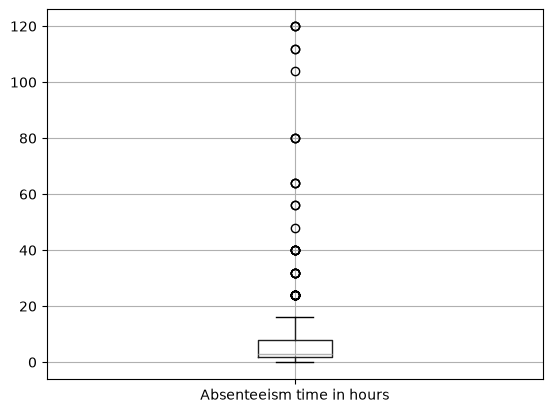

In [7]:
import matplotlib.pyplot as plt
print(df_clean["Absenteeism time in hours"].describe())
df_clean.boxplot(column="Absenteeism time in hours")
plt.show()

In [8]:
col = df_clean["Absenteeism time in hours"]
q1, q3 = col.quantile(0.25), col.quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
print("Upper limit:", upper)
print("Outliers above the limit:", (col > upper).sum())

Upper limit: 17.0
Outliers above the limit: 44


In [9]:
df_clean.columns = df_clean.columns.str.strip().str.lower().str.replace("/", "_per_").str.replace(" ", "_")
print(df_clean.columns.tolist())

['id', 'reason_for_absence', 'month_of_absence', 'day_of_the_week', 'seasons', 'transportation_expense', 'distance_from_residence_to_work', 'service_time', 'age', 'work_load_average_per_day', 'hit_target', 'disciplinary_failure', 'education', 'son', 'social_drinker', 'social_smoker', 'pet', 'weight', 'height', 'body_mass_index', 'absenteeism_time_in_hours']


In [10]:
df_clean = df_clean.copy()
cat_cols = ["reason_for_absence", "month_of_absence", "day_of_the_week", "seasons", "disciplinary_failure", "education", "social_drinker", "social_smoker"]
df_clean[cat_cols] = df_clean[cat_cols].astype("category")
print(df_clean.dtypes)

id                                    int64
reason_for_absence                 category
month_of_absence                   category
day_of_the_week                    category
seasons                            category
transportation_expense                int64
distance_from_residence_to_work       int64
service_time                          int64
age                                   int64
work_load_average_per_day             int64
hit_target                            int64
disciplinary_failure               category
education                          category
son                                   int64
social_drinker                     category
social_smoker                      category
pet                                   int64
weight                                int64
height                                int64
body_mass_index                       int64
absenteeism_time_in_hours             int64
dtype: object


In [ ]:
print(df_clean["reason_for_absence"].value_counts().sort_index())
print(df_clean["month_of_absence"].value_counts().sort_index())

reason_for_absence
0      43
1      16
2       1
3       1
4       2
5       3
6       8
7      15
8       6
9       4
10     25
11     26
12      8
13     55
14     19
15      2
16      3
17      1
18     21
19     40
21      6
22     37
23    142
24      3
25     31
26     33
27     47
28    108
Name: count, dtype: int64
month_of_absence
0      3
1     45
2     62
3     83
4     50
5     61
6     54
7     65
8     54
9     52
10    69
11    62
12    46
Name: count, dtype: int64


In [12]:
print("Reason 0 rows:", (df_clean["reason_for_absence"] == 0).sum())
print("Month 0 rows:", (df_clean["month_of_absence"] == 0).sum())

Reason 0 rows: 43
Month 0 rows: 3


In [13]:
before = len(df_clean)
df_clean = df_clean[df_clean["month_of_absence"] != 0].copy()
df_clean["month_of_absence"] = df_clean["month_of_absence"].cat.remove_unused_categories()
print("Rows removed:", before - len(df_clean))
print(df_clean.shape)

Rows removed: 3
(703, 21)


In [14]:
df_clean.to_csv("absenteeism_cleaned.csv", index=False)
print("Saved:", df_clean.shape)

Saved: (703, 21)
